# Chapter 10 — Neural Learning About Edges and Corners: Intro to Convolutional Neural Networks

**Reference:** *Grokking Deep Learning* — Andrew W. Trask

## Table of Contents
1. Reusing Weights in Multiple Places
2. The Convolutional Layer
3. A Simple Implementation in NumPy
4. Summary

## 1. Reusing Weights in Multiple Places

In a fully connected neural network, each input position can have its own connection weights. However, images contain spatial patterns that may appear in different locations.

For example, an edge can appear on the left, in the center, or on the right side of an image. A neural network should be able to recognize the same pattern regardless of its position.

Convolutional neural networks address this problem by reusing the same weights in multiple locations. This technique is called weight sharing.

### Why Weight Sharing Matters

- The same filter can detect similar patterns at different image positions.
- The network does not need a separate set of weights for every location.
- Fewer parameters may be needed compared with learning separate weights for every image position.
- The network can learn useful visual features such as edges and corners.

In [1]:
import numpy as np

# Contoh gambar sederhana
image = np.array([
    [1, 2, 1, 0, 0],
    [2, 3, 2, 0, 0],
    [1, 2, 1, 0, 0],
    [0, 0, 0, 3, 2],
    [0, 0, 0, 2, 3]
])

# Filter yang sama akan digunakan di setiap lokasi
kernel = np.array([
    [1, 0],
    [0, -1]
])

print("Image:")
print(image)

print("\nKernel:")
print(kernel)

Image:
[[1 2 1 0 0]
 [2 3 2 0 0]
 [1 2 1 0 0]
 [0 0 0 3 2]
 [0 0 0 2 3]]

Kernel:
[[ 1  0]
 [ 0 -1]]


## 2. The Convolutional Layer

A convolutional layer applies a small matrix called a filter or kernel to an input image.

The filter moves across the image. At each position, its values are multiplied by the corresponding image values, and the products are added together.

This operation produces an output called a feature map.

### Main Components

- **Input image:** The numerical representation of an image.
- **Filter or kernel:** A small matrix containing weights used to detect patterns.
- **Stride:** The number of pixels the filter moves at each step.
- **Feature map:** The output generated by applying the filter to the image.

In deep-learning libraries, the operation commonly called convolution is generally implemented as cross-correlation, meaning the filter is applied without flipping its values.

In [2]:
import numpy as np

def conv2d_valid(image, kernel):
    image = np.asarray(image, dtype=float)
    kernel = np.asarray(kernel, dtype=float)

    image_height, image_width = image.shape
    kernel_height, kernel_width = kernel.shape

    if kernel_height > image_height or kernel_width > image_width:
        raise ValueError("Kernel tidak boleh lebih besar dari image.")

    output_height = image_height - kernel_height + 1
    output_width = image_width - kernel_width + 1

    output = np.zeros((output_height, output_width))

    for i in range(output_height):
        for j in range(output_width):
            patch = image[
                i:i + kernel_height,
                j:j + kernel_width
            ]

            output[i, j] = np.sum(patch * kernel)

    return output


image = np.array([
    [1, 2, 1, 0, 0],
    [2, 3, 2, 0, 0],
    [1, 2, 1, 0, 0],
    [0, 0, 0, 3, 2],
    [0, 0, 0, 2, 3]
])

kernel = np.array([
    [1, 0],
    [0, -1]
])

feature_map = conv2d_valid(image, kernel)

print("Input Image:")
print(image)

print("\nKernel:")
print(kernel)

print("\nFeature Map:")
print(feature_map)

Input Image:
[[1 2 1 0 0]
 [2 3 2 0 0]
 [1 2 1 0 0]
 [0 0 0 3 2]
 [0 0 0 2 3]]

Kernel:
[[ 1  0]
 [ 0 -1]]

Feature Map:
[[-2.  0.  1.  0.]
 [ 0.  2.  2.  0.]
 [ 1.  2. -2. -2.]
 [ 0.  0. -2.  0.]]


### Understanding the Convolution Process

The function `conv2d_valid()` performs the following operations:

1. Receives an input image and a kernel.
2. Determines the dimensions of the output.
3. Moves the kernel across the input image.
4. Extracts a small image patch at each position.
5. Multiplies the patch by the kernel element by element.
6. Adds the multiplication results and stores the value in the feature map.

The kernel weights are reused at every position. This demonstrates the basic principle of weight sharing in convolutional neural networks.

The implementation uses a valid operation, so it does not add padding around the input image.

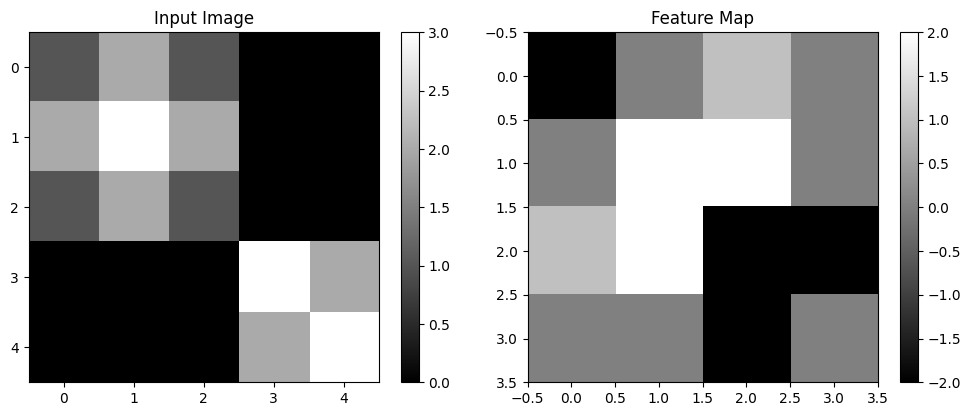

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Input Image")
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(feature_map, cmap="gray")
plt.title("Feature Map")
plt.colorbar()

plt.tight_layout()
plt.show()

## 3. Summary

In this chapter, we explored the basic ideas behind convolutional neural networks.

Key points:

- Convolutional neural networks are designed to process spatial patterns in images.
- Weight sharing allows the same filter weights to be reused at multiple image locations.
- A convolutional layer applies a filter across an input image.
- The output of the operation is called a feature map.
- NumPy can be used to implement a simple two-dimensional convolution operation.
- Filters can help identify visual patterns, including edges and corners.

The main idea is that convolutional neural networks can learn visual features by applying shared filters across different parts of an image.